# 03 – E1: MobileNetV2 congelado (feature extraction)
**Pregunta que responde:** ¿qué aporta el aprendizaje por transferencia frente al baseline E0?

**Diseño:** MobileNetV2 preentrenado en ImageNet, **todas sus capas congeladas**.
Solo se entrena la cabeza clasificadora (Dropout + Dense de 5 clases).
Mismos datos, semilla, tamaño, batch, optimizador y presupuesto de épocas que E0.

> **Hipótesis E1** (copiarla desde `protocolo.md` ANTES de ejecutar):
> Creemos que MobileNetV2 congelado superará claramente a E0 en macro-F1 y convergerá en menos épocas, porque los filtros aprendidos en ImageNet (bordes, texturas, cambios de color) sirven para describir lesiones en hojas aunque nunca haya visto yuca. Esperamos que la mejora sea mayor en las clases minoritarias y que persistan confusiones entre CBSD, CMD y hojas sanas, cuyos síntomas tempranos se parecen. Lo veremos comparando el F1 por clase de E0 y E1.

> Para la revisión del día 7 basta una **ejecución parcial** (por ejemplo `EPOCHS = 3`).
> La ejecución completa se hace después con el mismo presupuesto que E0.

In [5]:
# ============================================================
# CONFIGURACIÓN DEL PROTOCOLO (igual en todos los notebooks)
# ============================================================
import os, time, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

SEED = 42          # semilla fija -> resultados reproducibles
IMG = 224          # tamaño de entrada estándar de MobileNetV2 / ResNet
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)   # fija la semilla de Python, NumPy y TensorFlow
os.makedirs("results", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
# Instalar dependencia faltante para la compatibilidad de TFDS
!pip install -q importlib_resources

# ============================================================
# CARGA DEL DATASET (particiones oficiales de TFDS)
# ============================================================
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    as_supervised=True,      # devuelve pares (imagen, etiqueta)
    with_info=True,
)
CLASES = info.features["label"].names   # ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
N_CLASES = len(CLASES)
print("Clases:", CLASES)
print("Train:", info.splits["train"].num_examples,
      "| Val:", info.splits["validation"].num_examples,
      "| Test:", info.splits["test"].num_examples)

Clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Train: 5656 | Val: 1889 | Test: 1885


In [7]:
# ============================================================
# ELIMINAR DUPLICADOS Y ETIQUETAS CONTRADICTORIAS (evita fuga de datos)
# ============================================================
# EDA: imágenes idénticas repetidas dentro y entre particiones
# (10 de prueba también estaban en entrenamiento) y 18 imágenes repetidas
# con ETIQUETAS DISTINTAS (ruido de etiquetado).
# Criterio:
#   1) Toda imagen cuya huella (MD5) aparece con más de una etiqueta se quita de todas las particiones.
#   2) Se recorre train -> validation -> test y se quita toda imagen ya vista.
def huellas_etiquetas(ds):
    return [(hashlib.md5(img.tobytes()).hexdigest(), int(y)) for img, y in tfds.as_numpy(ds)]

parts = {"train": ds_train, "validation": ds_val, "test": ds_test}
he = {p: huellas_etiquetas(d) for p, d in parts.items()}

etiquetas_por_huella = {}
for p in he:
    for hh, y in he[p]:
        etiquetas_por_huella.setdefault(hh, set()).add(y)
contradictorias = {hh for hh, ys in etiquetas_por_huella.items() if len(ys) > 1}
print("Huellas con etiquetas contradictorias:", len(contradictorias))

vistos, mascaras = set(), {}
for p in ["train", "validation", "test"]:
    keep = []
    for hh, _ in he[p]:
        keep.append(hh not in vistos and hh not in contradictorias)
        vistos.add(hh)
    mascaras[p] = np.array(keep)
    print(f"{p}: se excluyen {(~mascaras[p]).sum()} -> quedan {mascaras[p].sum()}")

def filtrar(ds, keep):
    keep_t = tf.constant(keep)
    return (ds.enumerate()
              .filter(lambda i, xy: tf.gather(keep_t, i))
              .map(lambda i, xy: xy))

ds_train = filtrar(ds_train, mascaras["train"])
ds_val = filtrar(ds_val, mascaras["validation"])
ds_test = filtrar(ds_test, mascaras["test"])

with open("results/indices_excluidos_final.json", "w") as f:
    json.dump({p: np.where(~m)[0].tolist() for p, m in mascaras.items()}, f)

Huellas con etiquetas contradictorias: 18
train: se excluyen 36 -> quedan 5620
validation: se excluyen 13 -> quedan 1876
test: se excluyen 11 -> quedan 1874


In [8]:
# ============================================================
# PIPELINE: redimensionar a 224x224, guardar en caché, agrupar en lotes
# ============================================================
# - Se redimensiona y se guarda en uint8 (0-255) para ahorrar memoria.
# - La normalización NO se hace aquí: va dentro de cada modelo,
#   porque cada backbone espera una escala distinta.
# - Solo el entrenamiento se baraja. Validación y prueba mantienen su orden
#   (así las etiquetas reales coinciden con las predicciones).
# - NO hay augmentation en validación ni prueba.
def preparar(ds, entrenamiento=False):
    ds = ds.map(lambda x, y: (tf.cast(tf.image.resize(x, (IMG, IMG)), tf.uint8), y),
                num_parallel_calls=AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(2000, seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y),
                             num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train = preparar(ds_train, entrenamiento=True)
val = preparar(ds_val)
test = preparar(ds_test)

# Etiquetas reales de validación y prueba (en el mismo orden que las predicciones)
y_val = np.concatenate([y.numpy() for _, y in val])
y_test = np.concatenate([y.numpy() for _, y in test])
print("Etiquetas val:", y_val.shape, "| test:", y_test.shape)

Etiquetas val: (1876,) | test: (1874,)


In [9]:
# ============================================================
# FUNCIONES DE EVALUACIÓN (las mismas para todos los experimentos)
# ============================================================
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

def evaluar(model, ds, y_true, nombre, particion):
    """Calcula métricas, guarda la matriz de confusión y devuelve un diccionario."""
    t0 = time.time()
    probs = model.predict(ds, verbose=0)
    t_inf = time.time() - t0
    y_pred = probs.argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    reporte = classification_report(y_true, y_pred, target_names=CLASES,
                                    digits=3, output_dict=True, zero_division=0)

    print(f"\n===== {nombre} – {particion} =====")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=CLASES, digits=3, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{nombre} – matriz de confusión ({particion})")
    plt.tight_layout()
    plt.savefig(f"results/{nombre}_matriz_{particion}.png", dpi=120)
    plt.show()

    # Se guardan las predicciones para poder recalcular métricas sin reentrenar
    np.save(f"results/{nombre}_ypred_{particion}.npy", y_pred)
    np.save(f"results/{nombre}_probs_{particion}.npy", probs)

    return {
        "accuracy": round(float(acc), 4),
        "macro_f1": round(float(macro_f1), 4),
        "f1_por_clase": {c: round(reporte[c]["f1-score"], 4) for c in CLASES},
        "recall_por_clase": {c: round(reporte[c]["recall"], 4) for c in CLASES},
        "inferencia_ms_por_imagen": round(1000 * t_inf / len(y_true), 3),
    }

def graficar_curvas(hist, nombre):
    """Curvas de entrenamiento vs validación: sirven para ver sobreajuste."""
    h = hist.history
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(h["loss"], label="entrenamiento"); axs[0].plot(h["val_loss"], label="validación")
    axs[0].set_title("Pérdida (loss)"); axs[0].set_xlabel("época"); axs[0].legend()
    axs[1].plot(h["accuracy"], label="entrenamiento"); axs[1].plot(h["val_accuracy"], label="validación")
    axs[1].set_title("Accuracy"); axs[1].set_xlabel("época"); axs[1].legend()
    fig.suptitle(nombre); plt.tight_layout()
    plt.savefig(f"results/{nombre}_curvas.png", dpi=120)
    plt.show()

def tamano_modelo_mb(model, nombre):
    ruta = f"results/{nombre}.keras"
    model.save(ruta)
    return round(os.path.getsize(ruta) / 1e6, 2)

## Modelo E1
- `Rescaling(1/127.5, offset=-1)`: lleva los píxeles a −1…1, que es la **normalización que espera MobileNetV2**
  (equivale a `mobilenet_v2.preprocess_input`).
- `base.trainable = False`: el backbone queda **congelado**; sus pesos de ImageNet no cambian.
- `base(x, training=False)`: las capas BatchNormalization usan sus estadísticas originales.
- Cabeza: `GlobalAveragePooling2D` → `Dropout(0.2)` → `Dense(5, softmax)`.

In [10]:
NOMBRE = "E1_mobilenetv2_congelado"
EPOCHS = 10        # para la ejecución parcial del día 7 pueden poner 3
LR = 1e-3

base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                         input_shape=(IMG, IMG, 3))
base.trainable = False     # <- CONGELADO

entradas = tf.keras.Input(shape=(IMG, IMG, 3))
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)(entradas)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
salidas = tf.keras.layers.Dense(N_CLASES, activation="softmax")(x)
model = tf.keras.Model(entradas, salidas, name=NOMBRE)

model.compile(optimizer=tf.keras.optimizers.Adam(LR),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

entrenables = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Parámetros totales: {model.count_params():,} | entrenables: {entrenables:,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 2,264,389 | entrenables: 6,405


In [11]:
parar = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

t0 = time.time()
hist = model.fit(train, validation_data=val, epochs=EPOCHS, callbacks=[parar])
t_entrenamiento = time.time() - t0
print(f"\nTiempo de entrenamiento: {t_entrenamiento / 60:.1f} min | épocas ejecutadas: {len(hist.history['loss'])}")

Epoch 1/10
    176/Unknown 70s 195ms/step - accuracy: 0.5320 - loss: 1.2351

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


176/176 ━━━━━━━━━━━━━━━━━━━━ 80s 250ms/step - accuracy: 0.6155 - loss: 1.0264 - val_accuracy: 0.6919 - val_loss: 0.8088
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.7144 - loss: 0.7648 - val_accuracy: 0.7457 - val_loss: 0.7064
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.7340 - loss: 0.7074 - val_accuracy: 0.7521 - val_loss: 0.6938
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.7557 - loss: 0.6697 - val_accuracy: 0.7356 - val_loss: 0.7108
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.7676 - loss: 0.6419 - val_accuracy: 0.7591 - val_loss: 0.6720
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.7689 - loss: 0.6179 - val_accuracy: 0.7649 - val_loss: 0.6399
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.7810 - loss: 0.6037 - val_accuracy: 0.7607 - val_loss: 0.6618
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.7868 - loss: 0.5866 - val_accuracy: 0.

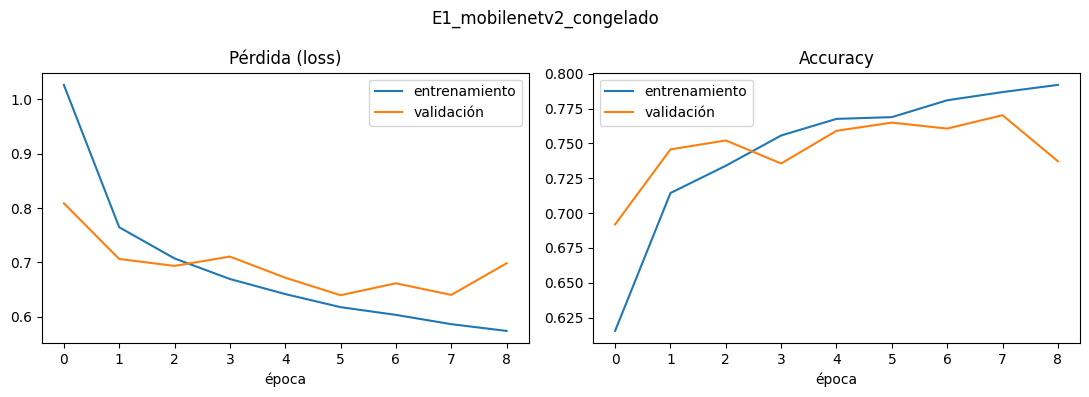

In [12]:
graficar_curvas(hist, NOMBRE)


===== E1_mobilenetv2_congelado – validacion =====
Accuracy: 0.7649 | Macro-F1: 0.6722
              precision    recall  f1-score   support

         cbb      0.642     0.344     0.448       151
        cbsd      0.724     0.745     0.734       478
         cgm      0.729     0.564     0.636       257
         cmd      0.805     0.921     0.859       884
     healthy      0.731     0.642     0.683       106

    accuracy                          0.765      1876
   macro avg      0.726     0.643     0.672      1876
weighted avg      0.757     0.765     0.754      1876



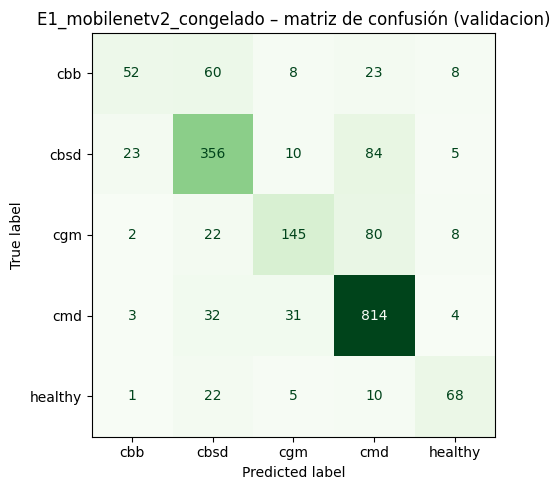

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



===== E1_mobilenetv2_congelado – prueba =====
Accuracy: 0.7641 | Macro-F1: 0.6706
              precision    recall  f1-score   support

         cbb      0.624     0.344     0.444       154
        cbsd      0.722     0.735     0.728       476
         cgm      0.742     0.581     0.652       253
         cmd      0.806     0.920     0.859       886
     healthy      0.705     0.638     0.670       105

    accuracy                          0.764      1874
   macro avg      0.720     0.644     0.671      1874
weighted avg      0.755     0.764     0.753      1874



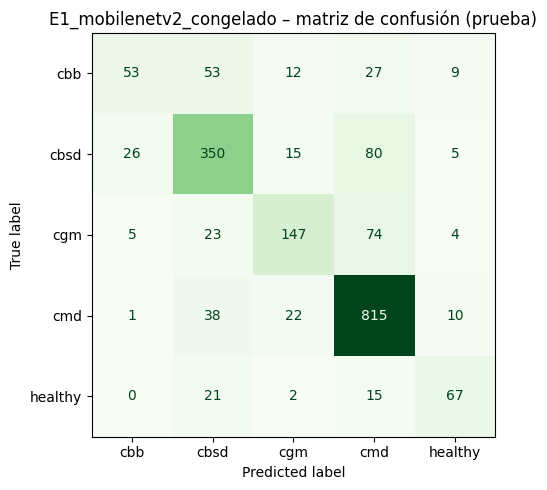

In [13]:
res_val = evaluar(model, val, y_val, NOMBRE, "validacion")
res_test = evaluar(model, test, y_test, NOMBRE, "prueba")

In [14]:
resultado = {
    "experimento": NOMBRE,
    "config": {"seed": SEED, "img": IMG, "batch": BATCH, "epochs_max": EPOCHS,
               "epochs_ejecutadas": len(hist.history["loss"]), "optimizador": "Adam", "lr": LR,
               "backbone": "MobileNetV2 (ImageNet), congelado"},
    "parametros": int(model.count_params()),
    "parametros_entrenables": entrenables,
    "tamano_mb": tamano_modelo_mb(model, NOMBRE),
    "tiempo_entrenamiento_min": round(t_entrenamiento / 60, 2),
    "validacion": res_val,
    "prueba": res_test,
}
with open(f"results/{NOMBRE}.json", "w") as f:
    json.dump(resultado, f, indent=2)
print(json.dumps(resultado, indent=2))

{
  "experimento": "E1_mobilenetv2_congelado",
  "config": {
    "seed": 42,
    "img": 224,
    "batch": 32,
    "epochs_max": 10,
    "epochs_ejecutadas": 9,
    "optimizador": "Adam",
    "lr": 0.001,
    "backbone": "MobileNetV2 (ImageNet), congelado"
  },
  "parametros": 2264389,
  "parametros_entrenables": 6405,
  "tamano_mb": 9.7,
  "tiempo_entrenamiento_min": 2.38,
  "validacion": {
    "accuracy": 0.7649,
    "macro_f1": 0.6722,
    "f1_por_clase": {
      "cbb": 0.4483,
      "cbsd": 0.734,
      "cgm": 0.636,
      "cmd": 0.8591,
      "healthy": 0.6834
    },
    "recall_por_clase": {
      "cbb": 0.3444,
      "cbsd": 0.7448,
      "cgm": 0.5642,
      "cmd": 0.9208,
      "healthy": 0.6415
    },
    "inferencia_ms_por_imagen": 5.307
  },
  "prueba": {
    "accuracy": 0.7641,
    "macro_f1": 0.6706,
    "f1_por_clase": {
      "cbb": 0.4435,
      "cbsd": 0.7284,
      "cgm": 0.6519,
      "cmd": 0.8593,
      "healthy": 0.67
    },
    "recall_por_clase": {
      "cbb": 

## Comparación preliminar E0 vs E1 (validación)

In [15]:
try:
    e0 = json.load(open("results/E0_baseline.json"))
    filas = [("Accuracy", "accuracy"), ("Macro-F1", "macro_f1")]
    print(f"{'métrica':25s}{'E0':>10s}{'E1':>10s}")
    for txt, k in filas:
        print(f"{txt:25s}{e0['validacion'][k]:10.4f}{res_val[k]:10.4f}")
    for c in CLASES:
        print(f"{'F1 ' + c:25s}{e0['validacion']['f1_por_clase'][c]:10.4f}{res_val['f1_por_clase'][c]:10.4f}")
    print(f"{'Tiempo entrenamiento (min)':25s}{e0['tiempo_entrenamiento_min']:10.2f}{resultado['tiempo_entrenamiento_min']:10.2f}")
    print(f"{'Tamaño (MB)':25s}{e0['tamano_mb']:10.2f}{resultado['tamano_mb']:10.2f}")
except FileNotFoundError:
    print("Sube results/E0_baseline.json a Colab (panel de archivos) para ver la comparación.")

métrica                          E0        E1
Accuracy                     0.6381    0.7649
Macro-F1                     0.3062    0.6722
F1 cbb                       0.0970    0.4483
F1 cbsd                      0.6500    0.7340
F1 cgm                       0.0000    0.6360
F1 cmd                       0.7842    0.8591
F1 healthy                   0.0000    0.6834
Tiempo entrenamiento (min)      2.97      2.38
Tamaño (MB)                    1.18      9.70


Errores en validación: 441 de 1876


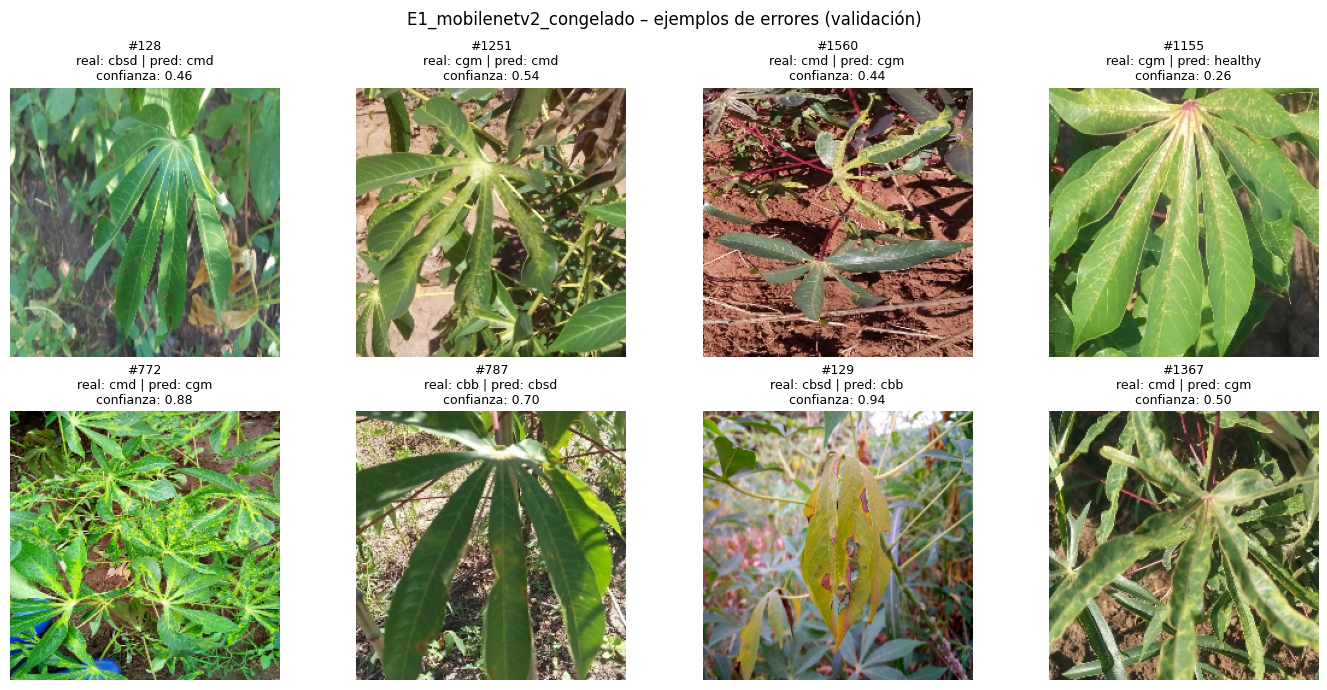

Índices mostrados: [128, 1251, 1560, 1155, 772, 787, 129, 1367]


In [16]:
# ============================================================
# INSPECCIÓN DE ERRORES (en VALIDACIÓN, no en prueba)
# ============================================================
# Se muestran imágenes mal clasificadas con la clase real, la predicha y la confianza.
# Ustedes deben mirarlas y anotar en registro_errores.md por qué creen que falló.
x_val_img = np.concatenate([x.numpy().astype("uint8") for x, _ in val])
probs_val = np.load(f"results/{NOMBRE}_probs_validacion.npy")
pred_val = probs_val.argmax(axis=1)

errores = np.where(pred_val != y_val)[0]
print(f"Errores en validación: {len(errores)} de {len(y_val)}")

rng = np.random.default_rng(SEED)
muestra = rng.choice(errores, size=min(8, len(errores)), replace=False)

fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axs.ravel(), muestra):
    ax.imshow(x_val_img[i]); ax.axis("off")
    ax.set_title(f"#{i}\nreal: {CLASES[y_val[i]]} | pred: {CLASES[pred_val[i]]}\n"
                 f"confianza: {probs_val[i].max():.2f}", fontsize=9)
plt.suptitle(f"{NOMBRE} – ejemplos de errores (validación)")
plt.tight_layout()
plt.savefig(f"results/{NOMBRE}_errores.png", dpi=120)
plt.show()
print("Índices mostrados:", muestra.tolist())

## Análisis E1

**Resultados (validación, 1.876 imágenes):** accuracy 0,765 · macro-F1 0,672 · 9 épocas (EarlyStopping; mejores pesos en la época 6) · 2,38 min · 2.264.389 parámetros, de los cuales solo 6.405 se entrenan · 9,7 MB · 5,3 ms por imagen. En prueba: accuracy 0,764 y macro-F1 0,671, coherentes con validación.

**Comparación con E0 (validación):**

| Métrica | E0 | E1 | Cambio |
|---|---|---|---|
| Accuracy | 0,638 | 0,765 | +0,127 |
| **Macro-F1** | **0,306** | **0,672** | **+0,366** |
| F1 CBB | 0,10 | 0,45 | +0,35 |
| F1 CBSD | 0,65 | 0,73 | +0,08 |
| F1 CGM | 0,00 | 0,64 | +0,64 |
| F1 CMD | 0,78 | 0,86 | +0,08 |
| F1 healthy | 0,00 | 0,68 | +0,68 |
| Tiempo de entrenamiento | 2,97 min | 2,38 min | menor |
| Tamaño | 1,18 MB | 9,7 MB | ×8 |
| Inferencia | 1,1 ms/img | 5,3 ms/img | ×5 |

**¿Se cumplió la hipótesis?** Sí. El macro-F1 más que se duplica y la mejora se concentra en las clases que E0 ignoraba (CGM y healthy pasan de 0 a ≈0,65). El modelo ahora predice las cinco clases. La brecha entre accuracy y macro-F1 se reduce de 0,33 a 0,09: ya no depende solo de la clase mayoritaria.

**Por qué funciona:** los filtros aprendidos en ImageNet ya detectan bordes, texturas y cambios de color, que sirven para describir moteados y manchas aunque la red nunca haya visto yuca. Solo hay que aprender a combinarlos (6.405 parámetros), lo que es posible con ≈5.600 imágenes.

**Curvas:** el accuracy de entrenamiento sigue subiendo (≈0,79) mientras la validación se estabiliza en ≈0,76 y su pérdida sube en la última época: la cabeza empieza a sobreajustarse. El EarlyStopping lo detuvo y restauró los pesos de la época 6.

**Errores (ver `registro_errores.md`):** la confusión principal sigue siendo CMD ↔ CGM, ahora en ambas direcciones (80 y 31). CBB es la clase más difícil (recall 0,34; 60 de 151 se confunden con CBSD). Algunos errores con confianza muy alta (0,88–0,94) sugieren etiquetas erróneas.

**Costo:** el modelo es más pesado y lento en inferencia, pero entrena más rápido que E0 porque casi todo está congelado. 5,3 ms por imagen sigue siendo muy rápido para el uso previsto.

**Conclusión preliminar:** el aprendizaje por transferencia aporta una mejora grande y clara. Queda por ver si el fine-tuning (E2) mejora CBB y la frontera CMD/CGM, y si otra arquitectura (E3) ofrece mejor equilibrio entre desempeño y costo.

Macro-F1 validación (recalculado): 0.6722
Accuracy validación (recalculado): 0.7649


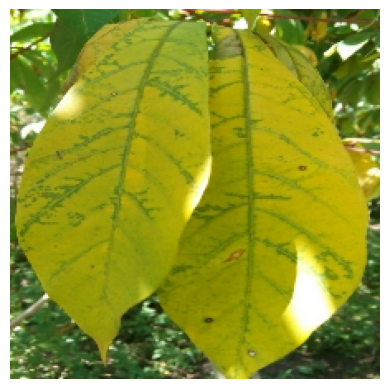

Clase real: cbsd
  cbsd     0.932
  cbb      0.068
  healthy  0.000
  cmd      0.000
  cgm      0.000
Predicción: cbsd


In [17]:
# ============================================================
# PARA LA REVISIÓN EN VIVO
# ============================================================
# (a) Recalcular el macro-F1 desde las predicciones guardadas, sin reentrenar
yp = np.load(f"results/{NOMBRE}_ypred_validacion.npy")
print("Macro-F1 validación (recalculado):", round(f1_score(y_val, yp, average="macro"), 4))
print("Accuracy validación (recalculado):", round(accuracy_score(y_val, yp), 4))

# (b) Predecir una sola imagen
def predecir_imagen(img_uint8):
    x = tf.image.resize(img_uint8, (IMG, IMG))[None, ...]     # agrega dimensión de lote
    p = model.predict(x, verbose=0)[0]
    for c, v in sorted(zip(CLASES, p), key=lambda t: -t[1]):
        print(f"  {c:8s} {v:.3f}")
    return CLASES[int(p.argmax())]

i = 0   # cambiar el índice para probar otra imagen de validación
plt.imshow(x_val_img[i]); plt.axis("off"); plt.show()
print("Clase real:", CLASES[y_val[i]])
print("Predicción:", predecir_imagen(x_val_img[i]))

# (c) Para probar con una foto propia en Colab:
# from google.colab import files
# subida = files.upload()
# ruta = list(subida.keys())[0]
# img = tf.keras.utils.img_to_array(tf.keras.utils.load_img(ruta)).astype("uint8")
# print(predecir_imagen(img))

In [18]:
# ============================================================
# DESCARGAR LOS RESULTADOS PARA SUBIRLOS A GITHUB (carpeta results/)
# ============================================================
# Los archivos .keras pesan; súbanlos solo si GitHub los acepta (<100 MB).
!zip -r -q results_E1.zip results
from google.colab import files
files.download("results_E1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>